# QPDK TSV flip-chip test chip: two CPW lines through all four metal faces (Quantcore PDK rebuild)

**What the chip is.** gdsfactory **quantum-rf-pdk** (QPDK) `qpdk/samples/tsv_flip_chip_test_chip.pic.yml`, with the
cells `qpdk/cells/tsv.py` (`tsv_transition_double_sided`) and `qpdk/cells/bump.py` (`bump_transition`,
`indium_bump_array`), <https://github.com/gdsfactory/quantum-rf-pdk>, **MIT licence** ("Copyright (c) 2024
gdsfactory", `LICENSE` of the local clone `build/external/quantum-rf-pdk`, read as data, never executed). Spec:
`docs/designs/qpdk/tsv_flip_chip_test_chip.md`. An interconnect test chip for a two-chip stack: two mirrored CPW
through lines, a (north) and b (south). Each line leaves a launcher on the bottom chip's front metal, drops through a
TSV pair to a backside underpass and comes back up, crosses to the top chip through an indium bump, goes through a
top-chip TSV to a serpentine on the top chip's backside, and returns the same way to a second launcher. Three
29 × 7 indium-bump arrays tie the two ground planes together. There are no qubits and no resonators.

This notebook **rebuilds** the chip with our components, routes and netlist on the Quantcore PDK; it is not a
replica. We distribute the rebuild under GPL-3.0.

**The four metal faces.** QPDK's four metal layers are KQC's four faces (`kqcircuits.defaults.default_faces` has
all four in this KQC version). The transitions record the face of each of their ports, and a route is drawn on the
face of the port it starts on, so no route below names its face:

| QPDK layer | where | KQC face | in the fab mask (PDK v3) |
|---|---|---|---|
| M1 | bottom chip, front (faces the top chip) | `1t1` | 1/0 etch, 3/0 keep-out, 700/0 TSVs |
| MB | bottom chip, back | `1b1` | not written: the PDK has no fab layer for it (`FabLayersDropped` warning) |
| M2 | top chip, front (faces down) | `2b1` | 800/0 etch, 700/0 TSVs |
| MB2 | top chip, back | `2t1` | not written (same warning) |
| bumps | between `1t1` and `2b1` | both | 801/0 indium, 802/0 under-bump metal |

| topic | QPDK source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | bottom chip 10 × 10 mm and top chip 6 × 6 mm, each with a 100 µm etched edge | the same 10 × 10 mm bottom chip with the Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "QPDK-TSV"); Designer = source + (5000, 5000) µm, so the top chip covers (2000…8000)² µm. The top chip's edge is not drawn: the PDK defines no frame for a flip-chip top chip (as in `flipmon_test_chip` and KQC's `demo_twoface`) |
| launchers | QPDK `launcher` at the chip edge | `BondPad`s with QPDK's launcher size (`QP.LAUNCHER`) on the pad rule, outer etch **100 µm** from the die edge (`edge="auto"`): the source's launchers already sit there |
| substrate | Si (QPDK's flip-chip backside stack) | sapphire 650 µm, εr 10.25 on both chips (the PDK stack; the sim groups use it, with the PDK's 8 µm chip gap) |
| TSV transition | `tsv_transition_double_sided`: a 100 µm taper into a 40 × 30 µm pad with a 24 µm gap on each face, 2 signal TSVs and 8 ground TSVs (10 × 20 µm slots) | `CpwTsvTransition` with its defaults, which are QPDK's (KQC `TsvEllipse` vias of 10 × 20 µm); `tsv_margin=2` µm (QPDK's via landing-pad margin) instead of KQC's 30 µm ground-grid avoidance |
| bump transition | `bump_transition`: 30 µm pads, 6 µm gap, 10 µm taper, one 15 µm bump, no ground bumps | `QcFlipChipConnectorRf` (KQC's `FlipChipConnectorRf` with a bump size): `connector_a=30, connector_b=6, bump_diameter=15, n_ground_bumps=0`; KQC's taper is as long as the pad (30 µm), and KQC draws an under-bump metal (⌀ 20 µm here, QPDK draws none) |
| ground bumps | 3 × `indium_bump_array`, 29 × 7, pitch 200 µm, ⌀ 15 µm | 3 × `d.array` of KQC `FlipChipConnectorDc` (⌀ 15 µm, under-bump metal ⌀ 20 µm as on the transition bumps) at the same 609 positions |
| routes | CPW 10 / 6 µm on every face, bend radius 100 µm | the same, one route per face piece, between the transitions' ports |
| cheese | none | the PDK band around the front-face features (chip `cheese: "auto"`), clear of the TSVs and bumps |

**How this notebook goes.** First the **Design**, one segment at a time with a picture of the chip so far: the die,
the four launchers, the sixteen transitions (twelve TSV, four bump), then the lines face by face (M1, MB, M2, MB2),
the ground bumps, and the whole chip with its sim groups and a picture of each face on its own. Then the same steps
as the Flow strip of the Quantcore KLayout plugin: **Check** (DRC, netlist) → **LOM** → **Simulate** → **Results** →
**Fab**.

This test chip has no circuit for the LOM (two through lines): that step says why in one sentence. Simulate exports a
Q3D and a driven job for one transition of each kind, on the faces they join; Results shows QPDK's own picture of
the chip and the FEM values once a solve is kept.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear.

## Setup

The imports, the output folders and the switches. `_qpdk` holds the QPDK cell defaults shared by the QPDK
notebooks (here the launcher size and the CPW bend radius). `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the full file). The segment pictures go to `build/snapshots/tsv_flip_chip_test_chip/` (not
kept in the repo), the final snapshots next to the notebook. `snapshot(..., hide=...)` renders a picture with some
layers switched off: the face pictures hide the layers of the other three faces.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations (there is no feedback step on this chip).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import json, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "qpdk"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
import _qpdk as QP                               # QPDK launcher size and CPW bend radius
from kqcircuits.defaults import default_faces
from quantcore_circuits.designer import Designer
from quantcore_circuits.live.snapshot import HIDE, snapshot
LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs/qpdk")              # design JSON + final snapshots
STEPS = Path("build/snapshots/tsv_flip_chip_test_chip")   # step-by-step snapshots (build/ is not kept in the repo)
DX, DY = 5000, 5000                              # Designer = QPDK source + (DX, DY): the source chip is centred on (0, 0)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (none on this chip)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip has no junctions; it uses the frame and pad rule, the stack (in the sim groups), the cheese and 3/0 rules
and the fab layer map, whose faces decide what reaches the mask (Fab 1).

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | 5 µm squares, 20 µm gaps, ≥ 4 µm from the 3/0 keep-outs: a band of 3 rows around them, or the whole die (`cheese: "chip"`); an original design's own rule or holes where it has them (chip param `cheese`: auto / pdk / chip / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The QPDK cell values.** `CpwTsvTransition`'s defaults are QPDK's `tsv_transition_double_sided` (the table lists
them); the only value this design sets is `tsv_margin`, KQC's ground-grid avoidance around each via (30 µm by default),
to QPDK's 2 µm via landing-pad margin. The bump transition is `QcFlipChipConnectorRf` with QPDK's `bump_transition`
values; KQC's cell always draws an under-bump metal, here 20 µm, between the 15 µm bump and the 30 µm pad. The array
bumps get the same bump and under-bump metal.

In [5]:
TSV = dict(tsv_margin=2.0)                                                       # the rest: CpwTsvTransition defaults
BUMP_RF = dict(connector_a=30, connector_b=6, bump_diameter=15, ubm_diameter=20, n_ground_bumps=0)  # bump_transition
BUMP_ARRAY = dict(columns=29, rows=7, pitch=200.0, bump_diameter=15, ubm_diameter=20)                 # indium_bump_array
FACES = ("1t1", "1b1", "2b1", "2t1")             # M1, MB, M2, MB2
R = QP.CPW_R                                     # QPDK cpw bend radius, 100 µm, on every face
print("KQC faces in this version:", list(default_faces))
display(Markdown(pcell_params_md("CpwTsvTransition", TSV, only=[
    "taper_length", "taper_length_back", "pad_width", "pad_gap", "pad_length", "n_signal_vias", "signal_via_pitch",
    "n_ground_vias_per_side", "ground_via_pitch", "ground_via_distance", "tsv_type", "tsv_diameter",
    "tsv_elliptical_width", "tsv_margin"])))

KQC faces in this version: ['1t1', '2b1', '1b1', '2t1']


**`CpwTsvTransition`** parameters:

| parameter | default | this design | meaning |
|---|---|---|---|
| `taper_length` | 100 | (default) | Front taper length (0: port at the pad) |
| `taper_length_back` | 100 | (default) | Back taper length (0: port at the pad) |
| `pad_width` | 40 | (default) | Pad centre-conductor width |
| `pad_gap` | 24 | (default) | Pad gap to ground (also closes the pad) |
| `pad_length` | 30 | (default) | Pad length along the line |
| `n_signal_vias` | 2 | (default) | Signal TSVs in the pad |
| `signal_via_pitch` | 20 | (default) | Signal TSV pitch across the line |
| `n_ground_vias_per_side` | 4 | (default) | Ground TSVs on each side of the pad |
| `ground_via_pitch` | 30 | (default) | Ground TSV pitch along the line |
| `ground_via_distance` | 15 | (default) | Ground TSV centres from the pad gap's outer edge |
| `tsv_elliptical_width` | 20 | (default) | TSV elliptical width |
| `tsv_type` | Tsv Ellipse | (default) | TSV type |
| `tsv_diameter` | 10 | (default) | TSV diameter |
| `tsv_margin` | 30 | 2.0 | TSV margin |

# Design: the layout, one segment at a time

A test chip for interconnects has no qubits, readout resonators, couplers or control lines, so those segments of the
template are not here. The test structures are the transitions themselves, and every route ends on one, so the
transitions come first: the die, the launchers, the sixteen transitions, then the routes face by face, the ground
bumps, and the whole chip. Each segment is one cell with one picture of the whole chip so far (all four faces drawn,
each in its own colour), some with a zoom.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame (device ID QPDK-TSV) |
| 2 | the four launchers on the front face (1t1), on the pad rule |
| 3 | the transitions: eight `CpwTsvTransition`s through the bottom chip (1t1 ↔ 1b1), four through the top chip (2b1 ↔ 2t1), four `QcFlipChipConnectorRf` bumps (1t1 ↔ 2b1) |
| 4 | M1 (1t1): the feed lines from the launchers and the lines from the in-up / out-down transitions to the bumps |
| 5 | MB (1b1): the four underpasses on the bottom chip's back |
| 6 | M2 (2b1): the four lines from the bumps to the top-chip transitions |
| 7 | MB2 (2t1): the two serpentines on the top chip's back |
| 8 | the ground bumps: three 29 × 7 indium-bump arrays between 1t1 and 2b1 |
| 9 | the whole chip: sim groups, the centring check, the save, and each face on its own |

## Design 1 · The die and its frame

`Designer(...)` starts the 10 × 10 mm chip (the source's bottom chip; it does not fit the 7.5 mm Quantcore die) with
the Quantcore die frame and the chip name "QPDK-TSV" (the device ID the frame writes on a free edge). No `with_grid`:
the source has no cheese, so the build draws the PDK band (chip `cheese` = `"auto"`) around the front-face features.

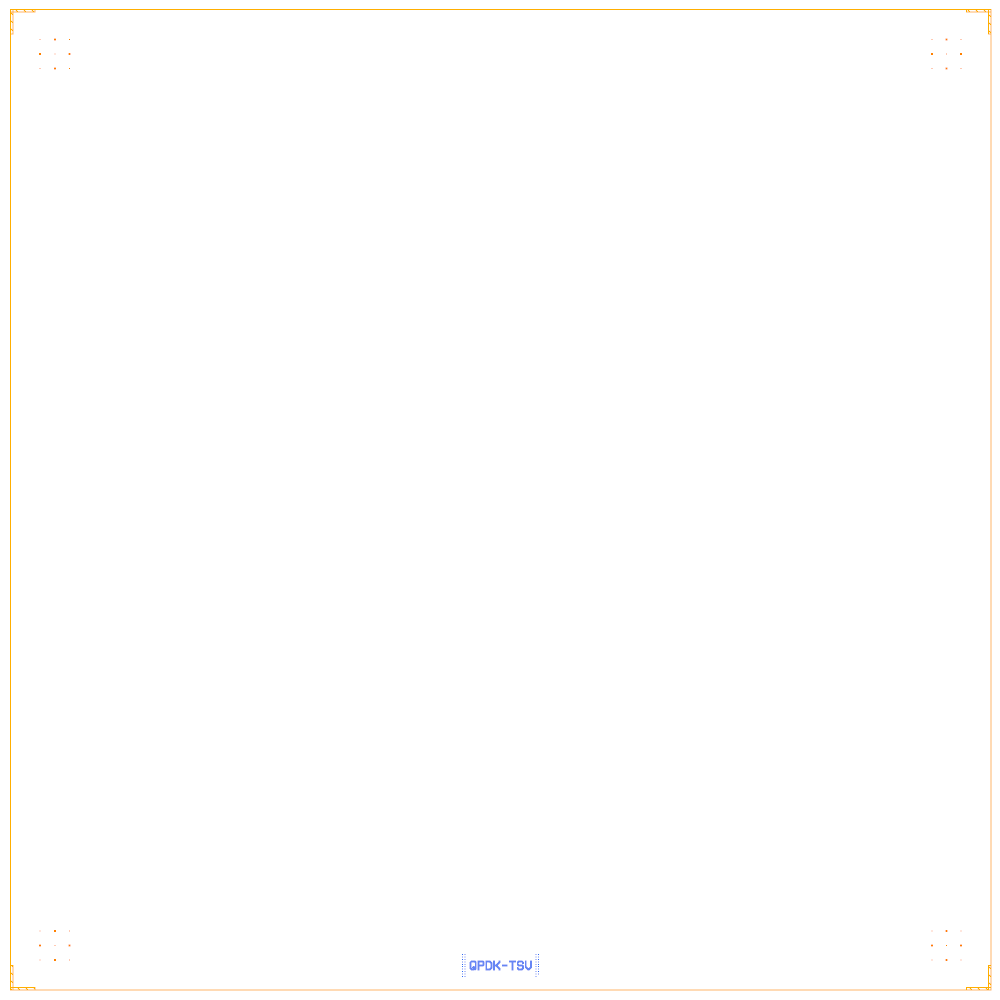

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/tsv_flip_chip_test_chip/s1_die.png')

In [6]:
d = Designer("tsv_flip_chip_test_chip", box=(0, 0, 10000, 10000), chip={"name_chip": "QPDK-TSV"}, live=LIVE)
CHIP = dict(size=(1000, 1000), width=400)        # the whole-chip picture of each segment
layout_step(d, STEPS / "s1_die.png", **CHIP)

## Design 2 · Bond pads: the four launchers and the pad rule

QPDK's `launcher` (a 200 × 200 µm pad on a 200 / 110 µm CPW and a 100 µm taper to the 10 / 6 µm line) is a
`BondPad` here (`QP.LAUNCHER`), on the front face. Source launchers: in at (−4900, ±1000), out at (4900, ±1000)
rotated 180°. **PDK rule:** a pad's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge;
`edge="auto"` applies it. A `BondPad` takes 410 µm from its outer etch edge to its port (`QP.LAUNCHER_DEPTH`; its gap
runs behind the pad), so with its port 410 µm in from the source launcher's outer end (100 µm from the die edge) it
already meets the rule; the ports sit 110 µm further in than QPDK's. The table measures each pad (✓ = 100 µm); the
second picture zooms on `PIN_A`.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PIN_A | `BondPad` | w | 100.0 | ✓ |
| POUT_A | `BondPad` | e | 100.0 | ✓ |
| PIN_B | `BondPad` | w | 100.0 | ✓ |
| POUT_B | `BondPad` | e | 100.0 | ✓ |

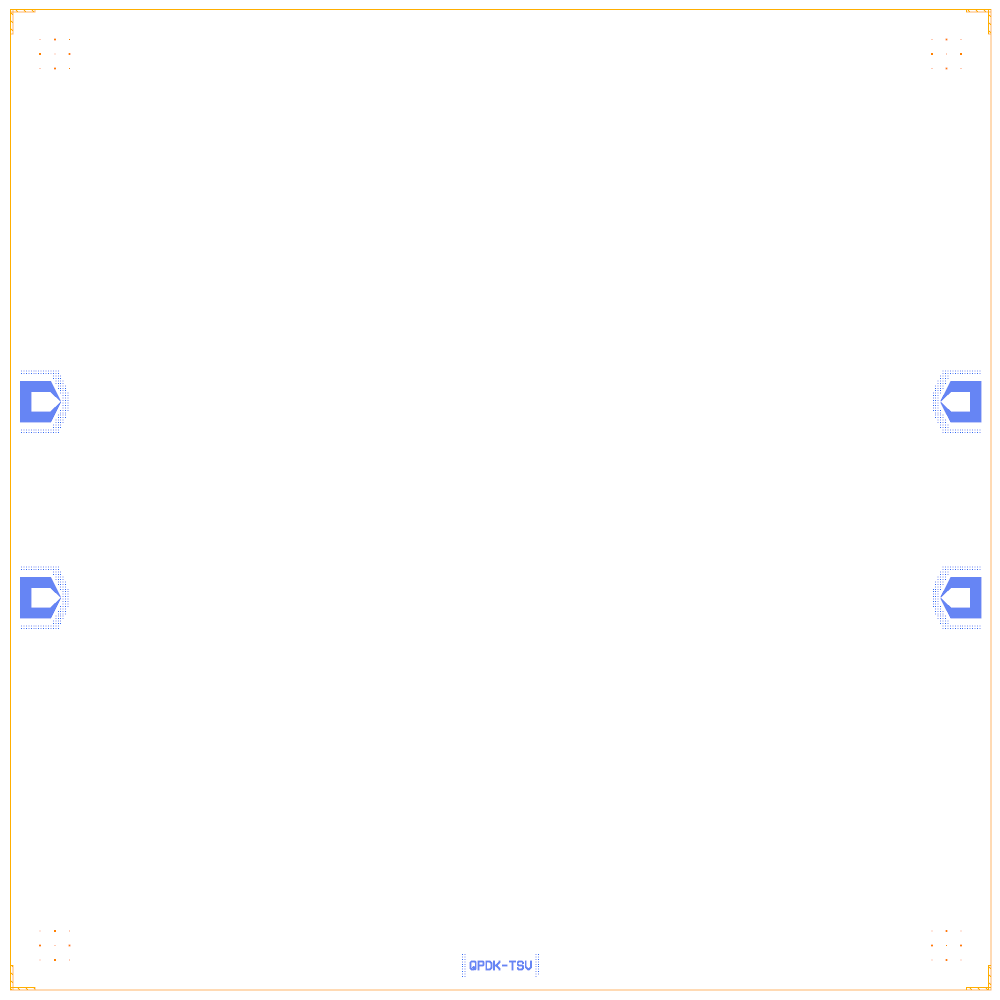

**On the chip so far:** 4 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 4 component(s) `PIN_A`, `POUT_A`, `PIN_B`, `POUT_B`.

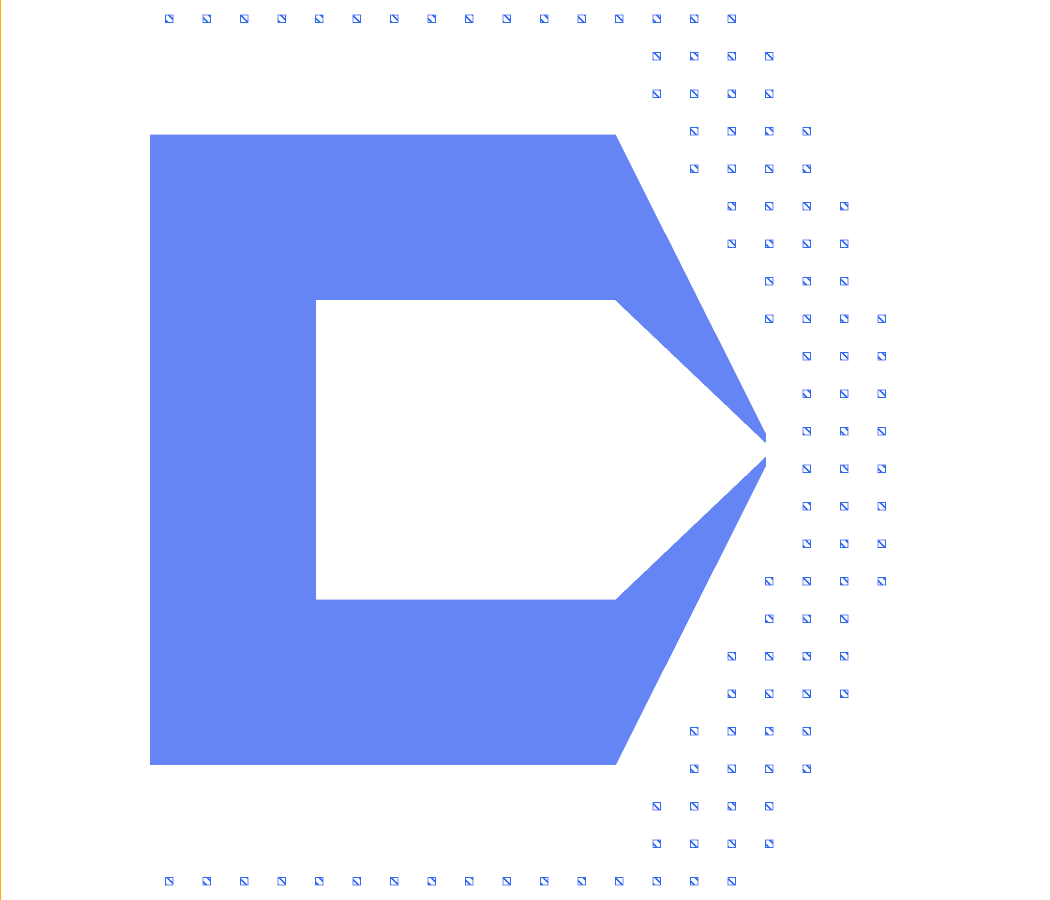

In [7]:
LINES = {"A": +1, "B": -1}                       # line a at source y = +1000, line b mirrored at y = -1000
with d.batch():
    for line, s in LINES.items():
        y = DY + s * 1000
        d.add(f"PIN_{line}", "BondPad", at=(DX - 5000 + 100 + QP.LAUNCHER_DEPTH, y), rot=270, edge="auto",
              **QP.LAUNCHER)                     # port faces east
        d.add(f"POUT_{line}", "BondPad", at=(DX + 5000 - 100 - QP.LAUNCHER_DEPTH, y), rot=90, edge="auto",
              **QP.LAUNCHER)                     # port faces west
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, STEPS / "s2_pads.png", **CHIP)
snap(d, STEPS / "s2_pin_a.png", box=(0, DY + 700, 700, DY + 1300), size=(1050, 900), width=320);

## Design 3 · The transitions: twelve TSV, four bump

**TSV transitions.** `CpwTsvTransition` is QPDK's `tsv_transition_double_sided`: the front CPW tapers over 100 µm into
a 40 × 30 µm pad (24 µm gap, closed on the far side), two signal vias carry it through the chip to the same pad on the
back face, and a 100 µm taper leads out of it in the opposite direction; four ground vias on each side stitch the two
ground planes. Port `a` is on the front face (`face_ids[0]`, facing −x at rotation 0), port `b` on the back face of
the same chip (facing +x); `face_ids=["2b1"]` puts it through the top chip (2b1 ↔ 2t1). The bottom chip has four per
line (in-down, in-up, out-down, out-up), the top chip two.

**Bump transitions.** `QcFlipChipConnectorRf` at the source's bump positions (∓2750, ±1000): port `a` on the bottom
chip (1t1), port `b` on the top chip (2b1), with QPDK's 30 µm pads, 6 µm gap and one 15 µm bump. Rotation 180 for
the way back.

The table lists line a's transitions with their ports and faces (from the built design); line b is the same at
y = 4000 µm. The pictures: the chip so far, then `TDN_IN_A` (front pad and taper in blue, back pad and taper in dark
red, the signal and ground vias) and `B_IN_A` (bottom-chip pad blue, top-chip pad red, the bump).

| transition | cell | at (µm) | rotation | port a | port b |
|---|---|---|---|---|---|
| `TDN_IN_A` | `CpwTsvTransition` | (900, 6000) | 0 | 1t1 (785) | 1b1 (1015) |
| `TUP_IN_A` | `CpwTsvTransition` | (1700, 6000) | 180 | 1t1 (1815) | 1b1 (1585) |
| `TT_IN_A` | `CpwTsvTransition` | (2800, 6000) | 0 | 2b1 (2685) | 2t1 (2915) |
| `B_IN_A` | `QcFlipChipConnectorRf` | (2250, 6000) | 0 | 1t1 (2205) | 2b1 (2295) |
| `TT_OUT_A` | `CpwTsvTransition` | (7200, 6000) | 180 | 2b1 (7315) | 2t1 (7085) |
| `TDN_OUT_A` | `CpwTsvTransition` | (8300, 6000) | 0 | 1t1 (8185) | 1b1 (8415) |
| `TUP_OUT_A` | `CpwTsvTransition` | (9100, 6000) | 180 | 1t1 (9215) | 1b1 (8985) |
| `B_OUT_A` | `QcFlipChipConnectorRf` | (7750, 6000) | 180 | 1t1 (7795) | 2b1 (7705) |

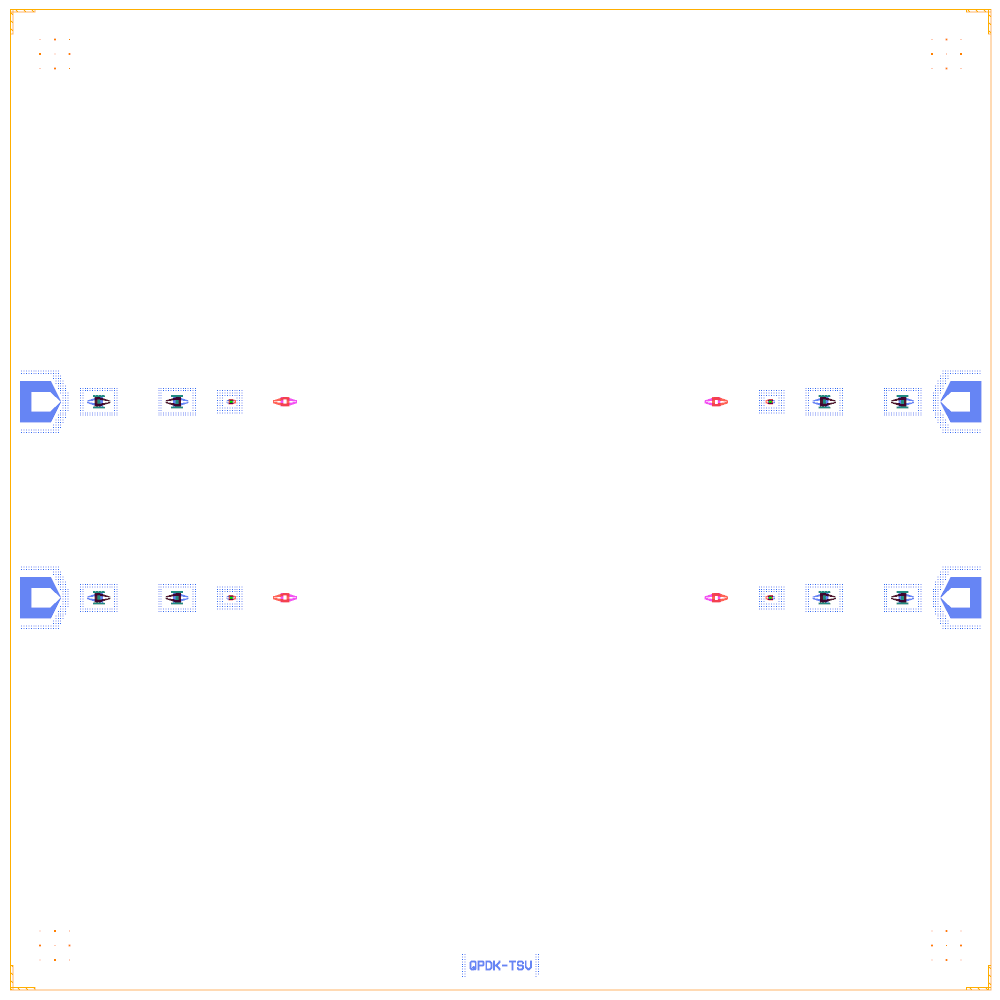

**On the chip so far:** 4 pads · 0 qubits · 16 other components · 0 routes · 0 declared couplings. **This step added** 16 component(s) `TDN_IN_A`, `TUP_IN_A`, `TT_IN_A`, `TT_OUT_A`, `TDN_OUT_A`, `TUP_OUT_A`, `B_IN_A`, `B_OUT_A` … (+8).

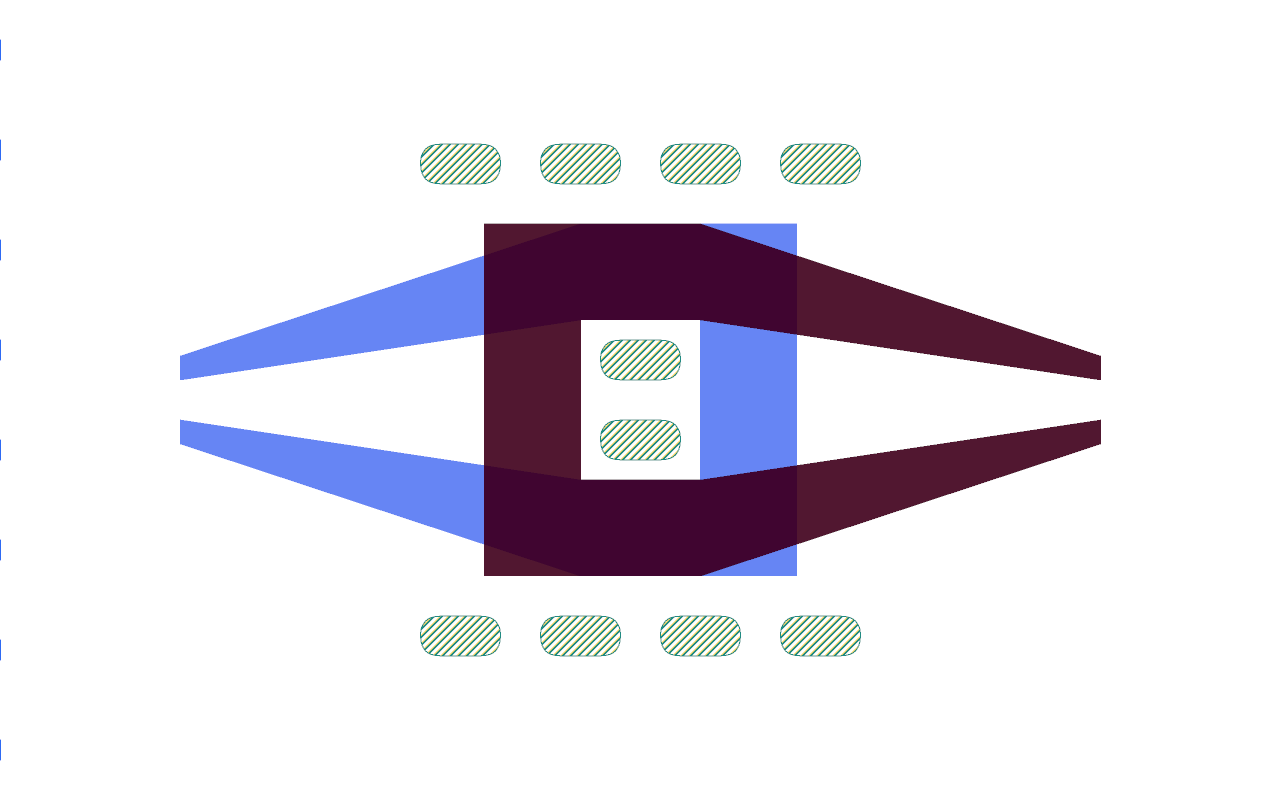

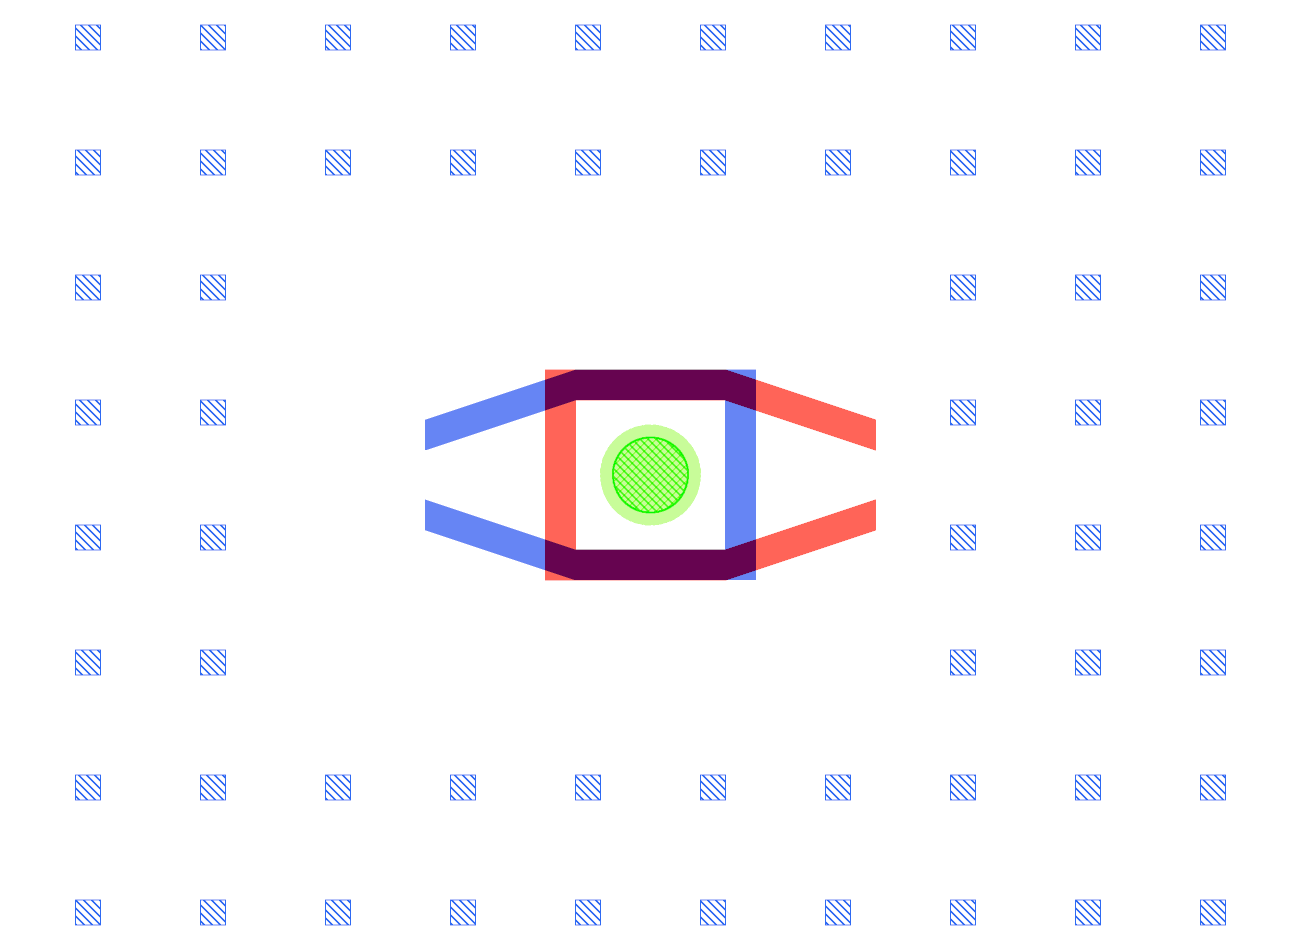

In [8]:
TRANSITIONS = (("TDN_IN", -4100, 0, "1t1"), ("TUP_IN", -3300, 180, "1t1"),      # source x, rotation, front face
               ("TT_IN", -2200, 0, "2b1"), ("TT_OUT", 2200, 180, "2b1"),
               ("TDN_OUT", 3300, 0, "1t1"), ("TUP_OUT", 4100, 180, "1t1"))
with d.batch():
    for line, s in LINES.items():
        y = DY + s * 1000
        for name, x, rot, front in TRANSITIONS:
            d.add(f"{name}_{line}", "CpwTsvTransition", at=(DX + x, y), rot=rot, face_ids=[front], **TSV)
        d.add(f"B_IN_{line}", "QcFlipChipConnectorRf", at=(DX - 2750, y), rot=0, **BUMP_RF)
        d.add(f"B_OUT_{line}", "QcFlipChipConnectorRf", at=(DX + 2750, y), rot=180, **BUMP_RF)
rebuild(d)
P = d.result.plan.all_ports()
display(Markdown("| transition | cell | at (µm) | rotation | port a | port b |\n|---|---|---|---|---|---|\n" + "\n".join(
    f"| `{n}` | `{d.data['instances'][n]['cell']}` | {tuple(d.data['instances'][n]['place']['at'])} | "
    f"{d.data['instances'][n]['place']['rot']:g} | {P[n + '.a'].face} ({P[n + '.a'].pos.x:g}) | "
    f"{P[n + '.b'].face} ({P[n + '.b'].pos.x:g}) |"
    for n in [f"{t[0]}_A" for t in TRANSITIONS[:3]] + ["B_IN_A"] + [f"{t[0]}_A" for t in TRANSITIONS[3:]] + ["B_OUT_A"])))
layout_step(d, STEPS / "s3_transitions.png", **CHIP)
snap(d, STEPS / "s3_tdn_in_a.png", box=(DX - 4100 - 160, DY + 1000 - 100, DX - 4100 + 160, DY + 1000 + 100),
     size=(1280, 800), width=420)
snap(d, STEPS / "s3_b_in_a.png", box=(DX - 2750 - 130, DY + 1000 - 95, DX - 2750 + 130, DY + 1000 + 95),
     size=(1300, 950), width=420);

## Design 4 · M1 (1t1): the front-face lines

On the bottom chip's front face each line has three pieces: the feed line from the launcher to the in-down
transition (QPDK `feed_in_*`), the line from the in-up transition to the bump (`bottom_in_*`), and on the way out the
line from the bump to the out-down transition (`bottom_out_*`) and the feed line to the out launcher (`feed_out_*`),
all straight. Each starts on a front-face port, so it is drawn on 1t1.

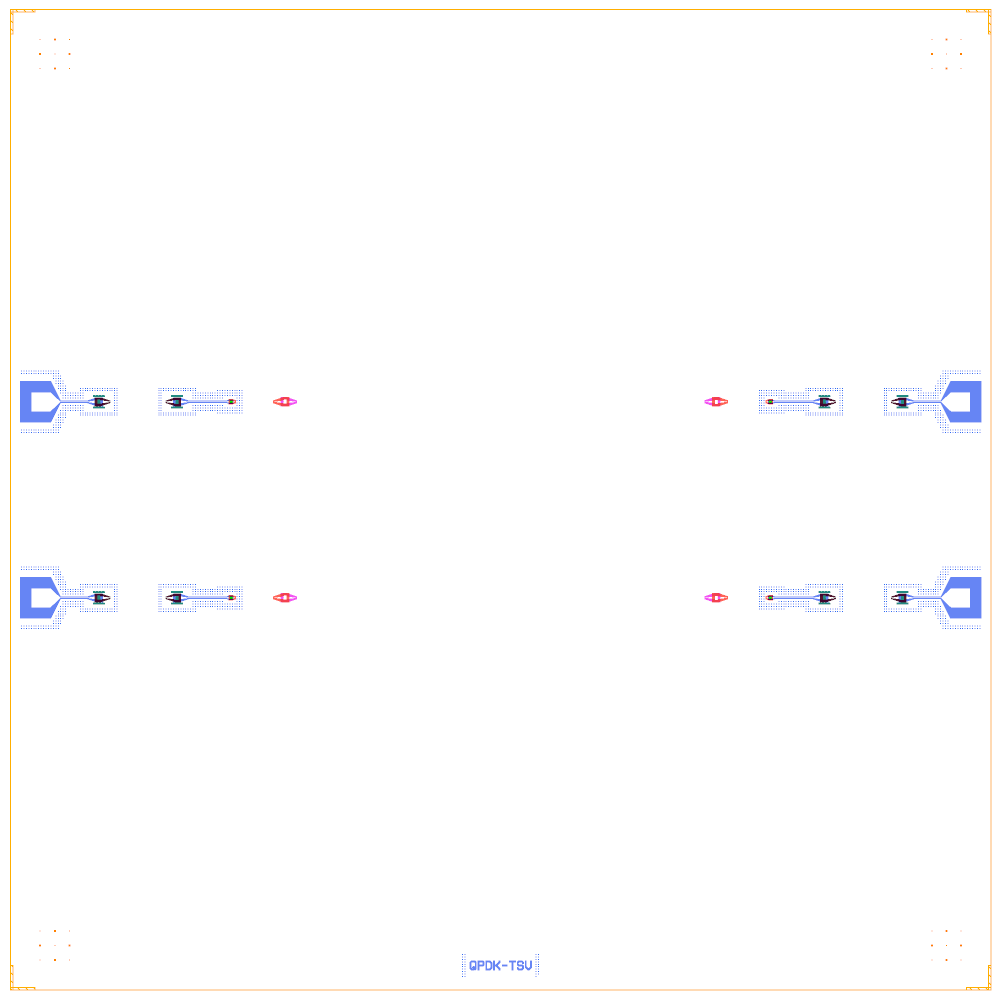

**On the chip so far:** 4 pads · 0 qubits · 16 other components · 8 routes · 0 declared couplings. **This step added** 8 route(s) `FEED_IN_A`, `BOT_IN_A`, `BOT_OUT_A`, `FEED_OUT_A`, `FEED_IN_B`, `BOT_IN_B`, `BOT_OUT_B`, `FEED_OUT_B`.

WindowsPath('build/snapshots/tsv_flip_chip_test_chip/s4_m1.png')

In [9]:
with d.batch():
    for line in LINES:
        d.route(f"FEED_IN_{line}", f"PIN_{line}.a", f"TDN_IN_{line}.a", r=R)
        d.route(f"BOT_IN_{line}", f"TUP_IN_{line}.a", f"B_IN_{line}.a", r=R)
        d.route(f"BOT_OUT_{line}", f"B_OUT_{line}.a", f"TDN_OUT_{line}.a", r=R)
        d.route(f"FEED_OUT_{line}", f"TUP_OUT_{line}.a", f"POUT_{line}.a", r=R)
layout_step(d, STEPS / "s4_m1.png", **CHIP)

## Design 5 · MB (1b1): the underpasses on the bottom chip's back

Between the in-down and the in-up transition (and the out pair) the line runs on the back face, from port `b` to port
`b`, with QPDK's waypoints: a 400 µm loop away from the line, 200 µm wide (source (−3800, ±1000) … (−3600, ±1000) and
(3600, …) … (3800, …); line b loops south). On the front face the line is interrupted there.

The router leaves every port straight for one bend radius (100 µm) before the first corner. QPDK's first corner is
185 µm from the transition's port, less than that stub plus the corner's own 100 µm, so each underpass also gets a
waypoint 20 µm out of each port, on the port's axis: a waypoint that close to the port is taken as the port's stub,
and the centre line is QPDK's. The zoom shows `TDN_IN_A` with both its lines: the feed line on 1t1 (blue) and the
underpass on 1b1 (dark red) leaving the other way.

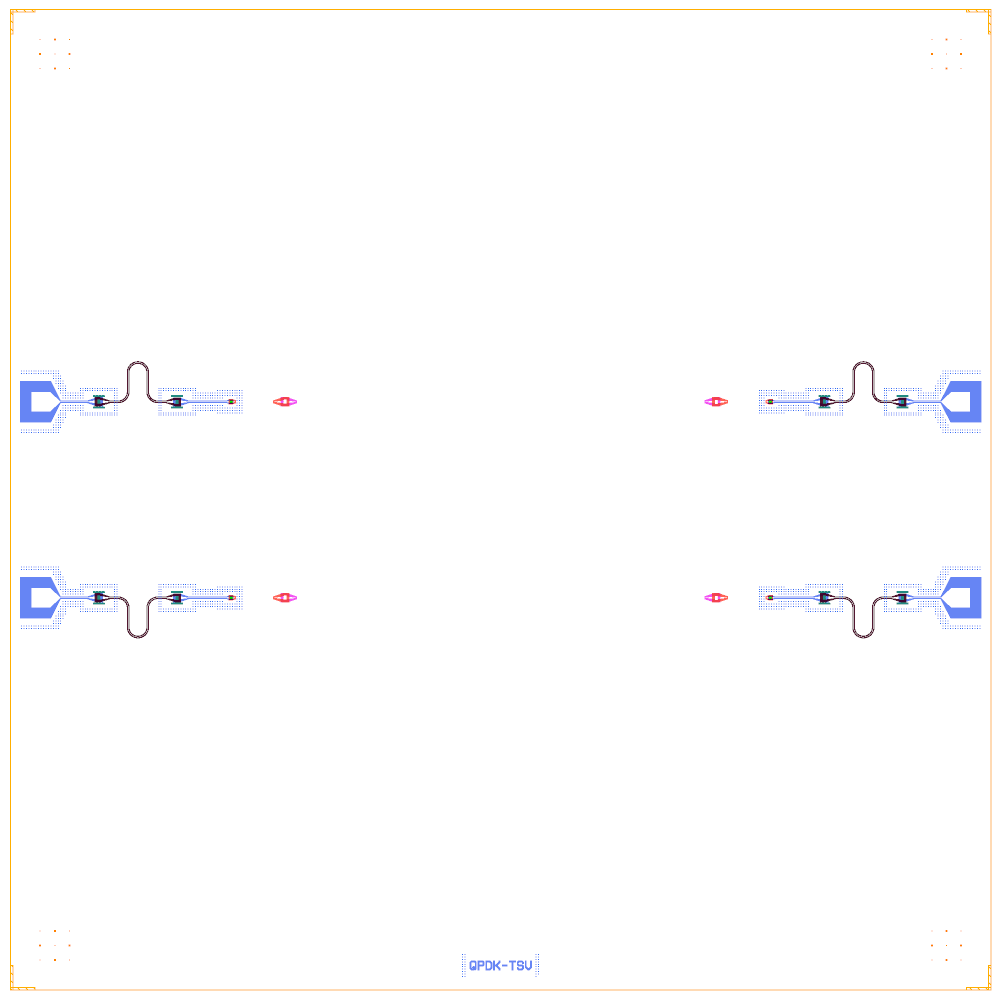

**On the chip so far:** 4 pads · 0 qubits · 16 other components · 12 routes · 0 declared couplings. **This step added** 4 route(s) `UNDER_IN_A`, `UNDER_OUT_A`, `UNDER_IN_B`, `UNDER_OUT_B`.

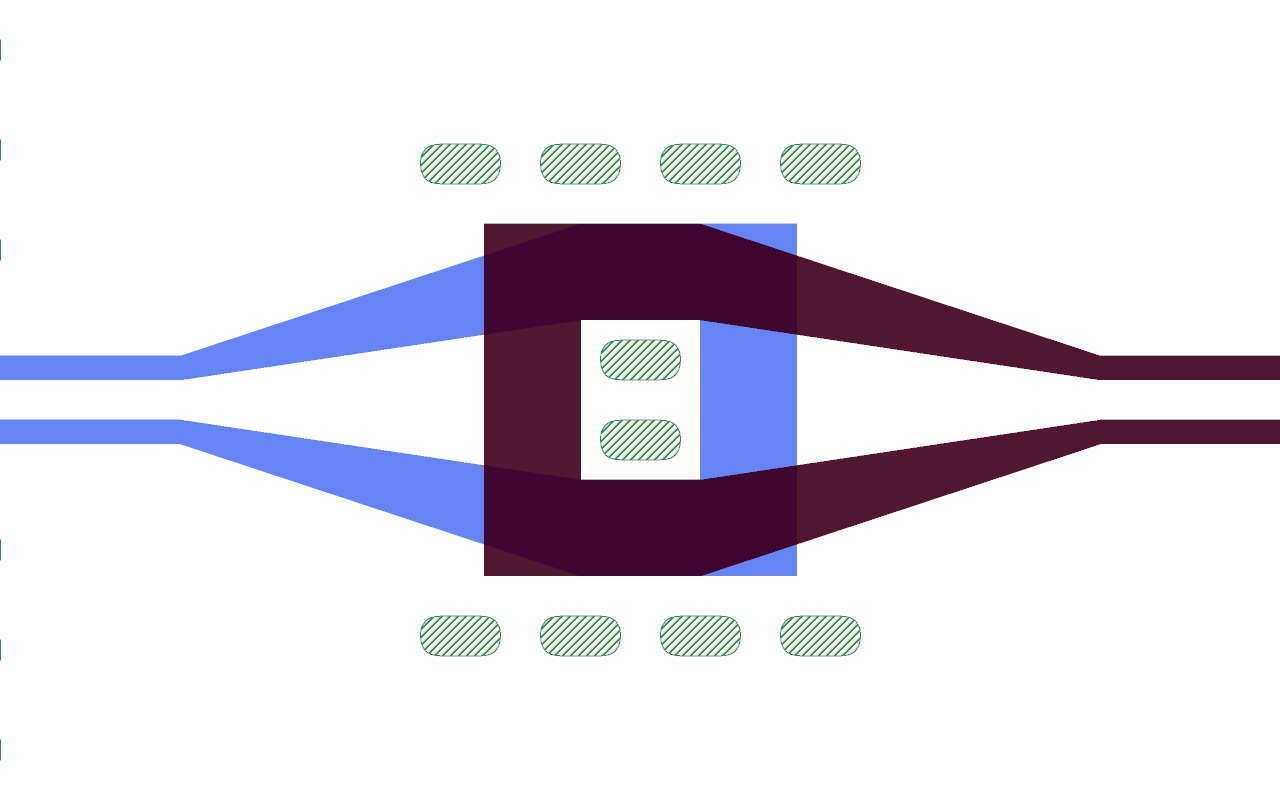

In [10]:
def underpass(name, a, b, x0, x1, y, s):
    """QPDK underpass_*: the back-face route from port b of transition a to port b of transition b, a loop 400 µm off
    the line between x0 and x1, with a waypoint 20 µm out of each port (the port's stub)."""
    xa, xb = P[f"{a}.b"].pos.x, P[f"{b}.b"].pos.x
    yu = y + s * 400
    d.route(name, f"{a}.b", f"{b}.b", r=R,
            nodes=[(xa + 20, y), (x0, y), (x0, yu), (x1, yu), (x1, y), (xb - 20, y)])


with d.batch():
    for line, s in LINES.items():
        y = DY + s * 1000
        underpass(f"UNDER_IN_{line}", f"TDN_IN_{line}", f"TUP_IN_{line}", DX - 3800, DX - 3600, y, s)
        underpass(f"UNDER_OUT_{line}", f"TDN_OUT_{line}", f"TUP_OUT_{line}", DX + 3600, DX + 3800, y, s)
layout_step(d, STEPS / "s5_mb.png", **CHIP)
snap(d, STEPS / "s5_tsv.png", box=(DX - 4100 - 160, DY + 1000 - 100, DX - 4100 + 160, DY + 1000 + 100),
     size=(1280, 800), width=520);

## Design 6 · M2 (2b1): the top chip's front face

From each bump's top-chip port to the top-chip TSV transition (QPDK `top_in_*`), and back from the second top-chip
transition to the second bump (`top_out_*`), straight. Both start on a 2b1 port. The zoom shows `B_IN_A` with its two
lines: the bottom-chip line (blue) ends at the bottom pad, the top-chip line (red) leaves the top pad.

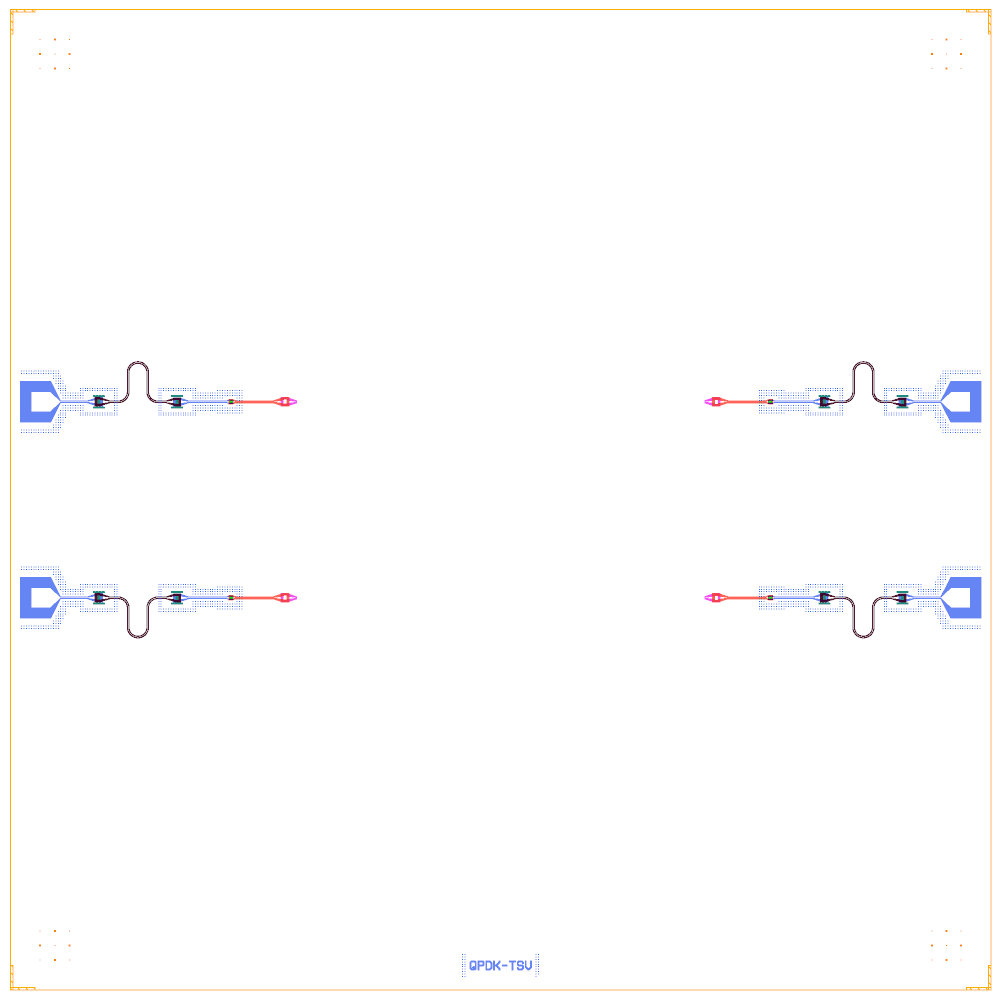

**On the chip so far:** 4 pads · 0 qubits · 16 other components · 16 routes · 0 declared couplings. **This step added** 4 route(s) `TOP_IN_A`, `TOP_OUT_A`, `TOP_IN_B`, `TOP_OUT_B`.

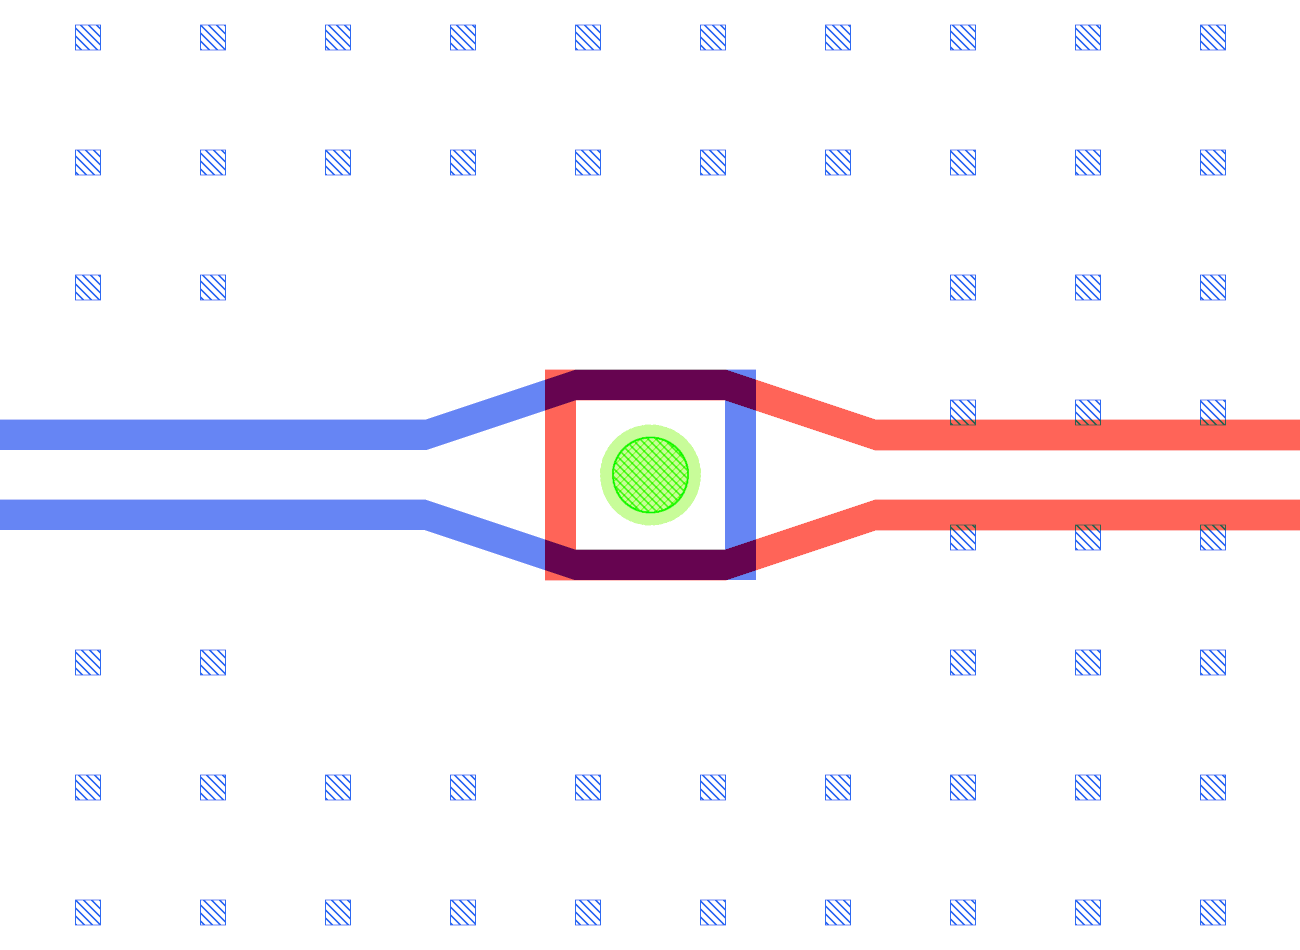

In [11]:
with d.batch():
    for line in LINES:
        d.route(f"TOP_IN_{line}", f"B_IN_{line}.b", f"TT_IN_{line}.a", r=R)
        d.route(f"TOP_OUT_{line}", f"TT_OUT_{line}.a", f"B_OUT_{line}.b", r=R)
layout_step(d, STEPS / "s6_m2.png", **CHIP)
snap(d, STEPS / "s6_bump.png", box=(DX - 2750 - 130, DY + 1000 - 95, DX - 2750 + 130, DY + 1000 + 95),
     size=(1300, 950), width=420);

## Design 7 · MB2 (2t1): the serpentines on the top chip's back

Between the two top-chip TSV transitions each line runs on the top chip's back face along QPDK's serpentine: x from
−1800 to 1800 µm (source) in 400 µm steps, legs between y = ±1000 and ±1600 µm, ten legs, the corners at the 100 µm
bend radius. Line a's serpentine goes north, line b's south. It sets the delay of the line.

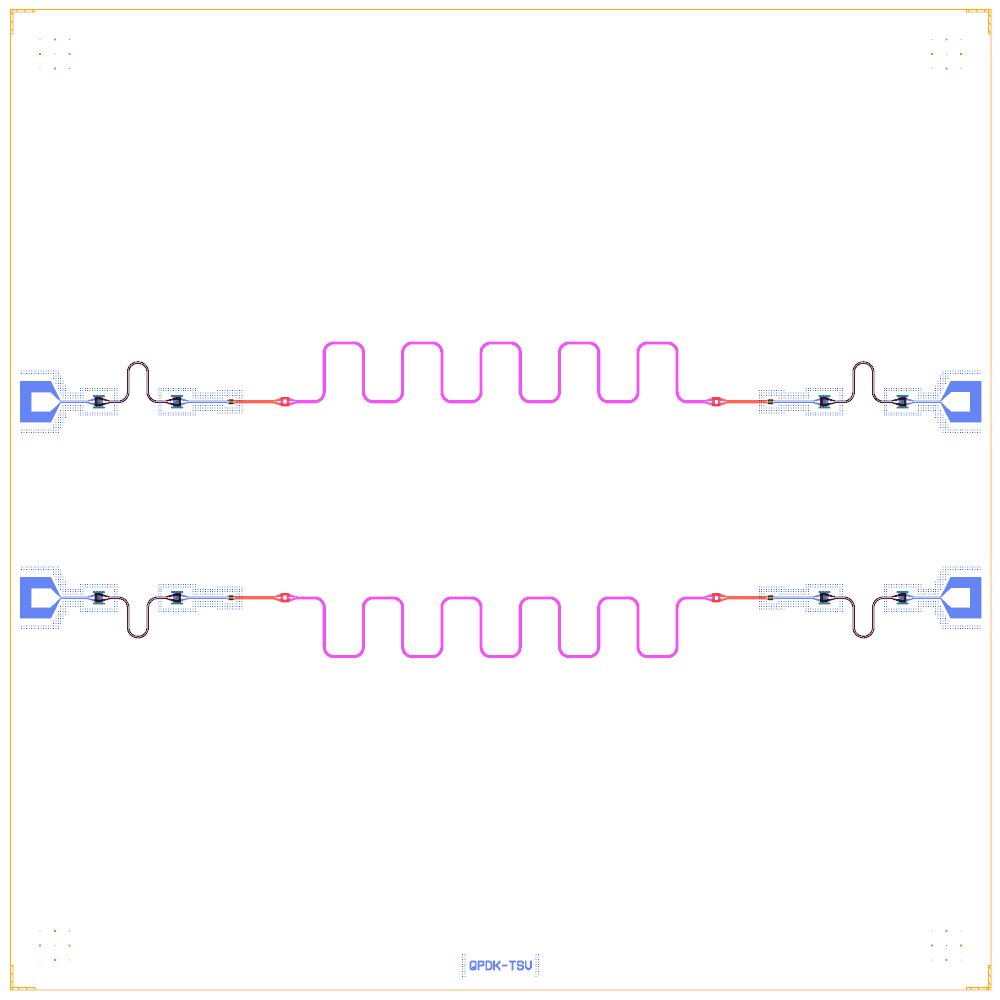

**On the chip so far:** 4 pads · 0 qubits · 16 other components · 18 routes · 0 declared couplings. **This step added** 2 route(s) `TOP_BACK_A`, `TOP_BACK_B`.

WindowsPath('build/snapshots/tsv_flip_chip_test_chip/s7_mb2.png')

In [12]:
with d.batch():
    for line, s in LINES.items():
        y, ys = DY + s * 1000, DY + s * 1600
        legs = []
        for k, x in enumerate(range(-1800, 1801, 400)):      # QPDK top_backside_* waypoints
            legs += [(DX + x, y), (DX + x, ys)] if k % 2 == 0 else [(DX + x, ys), (DX + x, y)]
        d.route(f"TOP_BACK_{line}", f"TT_IN_{line}.b", f"TT_OUT_{line}.b", r=R, nodes=legs)
layout_step(d, STEPS / "s7_mb2.png", **CHIP)

## Design 8 · The ground bumps: three 29 × 7 arrays

QPDK's `indium_bump_array(columns=29, rows=7, pitch=200)` at source (0, 0), (0, 2100) and (0, −2100): each array is
5600 × 1200 µm, centred, and the lines pass between them. Here each bump is a KQC `FlipChipConnectorDc` between 1t1
and 2b1 (⌀ 15 µm as in QPDK, under-bump metal ⌀ 20 µm), placed with `d.array` (instances `BUMPS_C_<column>_<row>`
and so on): 609 bumps.

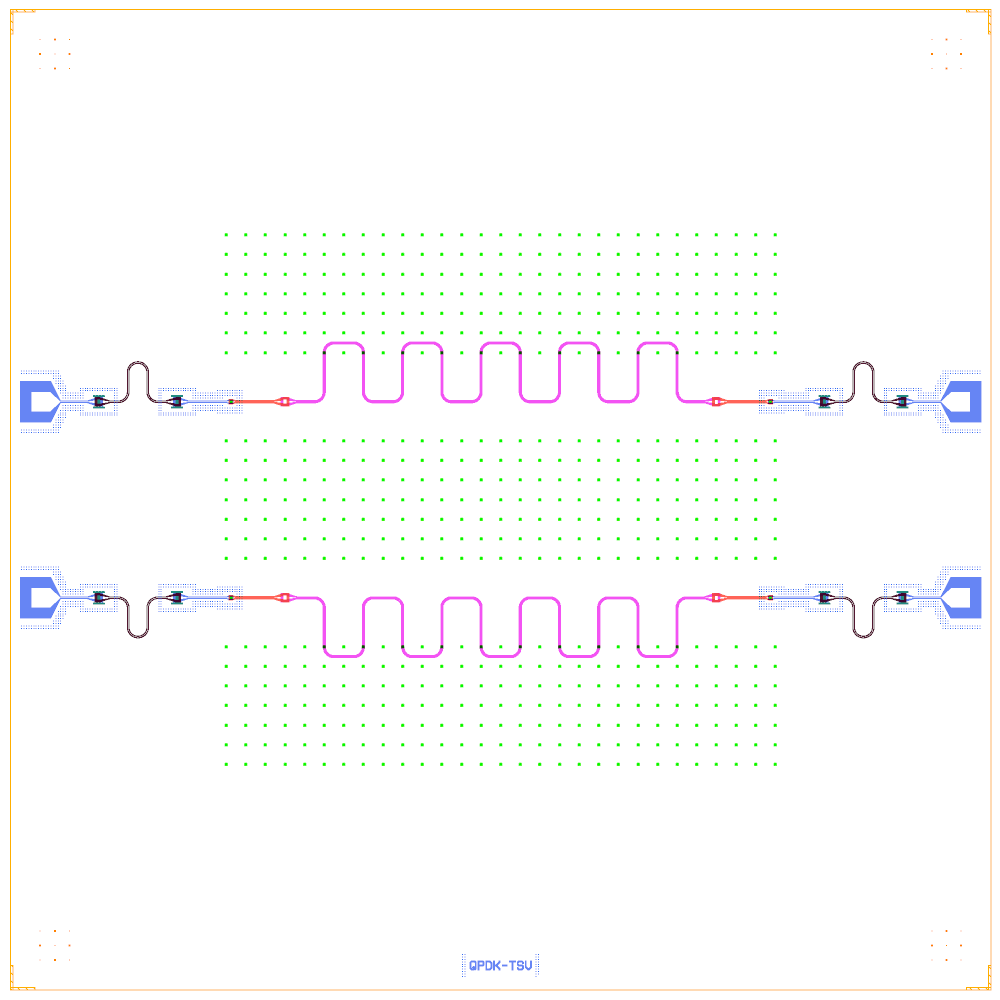

**On the chip so far:** 4 pads · 0 qubits · 625 other components · 18 routes · 0 declared couplings. **This step added** 609 component(s) `BUMPS_C_0_0`, `BUMPS_C_0_1`, `BUMPS_C_0_2`, `BUMPS_C_0_3`, `BUMPS_C_0_4`, `BUMPS_C_0_5`, `BUMPS_C_0_6`, `BUMPS_C_1_0` … (+601).

WindowsPath('build/snapshots/tsv_flip_chip_test_chip/s8_bumps.png')

In [13]:
nx, ny, p = BUMP_ARRAY["columns"], BUMP_ARRAY["rows"], BUMP_ARRAY["pitch"]
with d.batch():
    for name, yc in (("BUMPS_C", 0), ("BUMPS_N", 2100), ("BUMPS_S", -2100)):
        d.array(name, "FlipChipConnectorDc", origin=(DX - (nx - 1) / 2 * p, DY + yc - (ny - 1) / 2 * p), pitch=(p, p),
                shape=(nx, ny), bump_diameter=BUMP_ARRAY["bump_diameter"], ubm_diameter=BUMP_ARRAY["ubm_diameter"],
                face_ids=["1t1", "2b1"])
layout_step(d, STEPS / "s8_bumps.png", **CHIP)

## Design 9 · The whole chip: sim groups, centring, save, and each face on its own

**Sim groups.** One transition of each kind, on line a's way in, with the stubs of its two lines that the box cuts:
`TSV_IN_A` (`TDN_IN_A`, faces 1t1 and 1b1), `BUMP_IN_A` (`B_IN_A`, 1t1 and 2b1) and `TSV_TOP_A` (`TT_IN_A`, the top
chip's TSV: 2b1 and 2t1, with 1t1 below them). Each gets a Q3D C-matrix job and a driven (S-parameter) job, the
transmission and return loss of the transition the chip is made to measure. The 60 µm margin keeps every box edge
on a straight of the lines it cuts (the box edges are moved off bends only on 1t1).

`center_in_die` checks that the content sits centred in the die (the source is symmetric about its centre, so no
shift is expected). Then `save_design` writes `tsv_flip_chip_test_chip.json` and compares it with the file it replaces
(the previous run's): it should say *same design*.

The four pictures after the whole chip are the west half of line a, one face at a time (the other faces' layers
hidden; the die frame stays): **M1** (1t1) the launcher, the feed line, the front pads of the two bottom-chip
transitions and the line to the bump; **MB** (1b1) the underpass between the back pads; **M2** (2b1) the line from
the bump to the top-chip transition; **MB2** (2t1) the start of the serpentine. The bumps show on M1 and M2, the TSVs
on both faces of their chip. The top chip begins at x = 2000 µm.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/qpdk/tsv_flip_chip_test_chip.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer tsv_flip_chip_test_chip: 629 instances, 18 routes, live=False> → examples\designs\qpdk\tsv_flip_chip_test_chip.json
{'FEED_IN_A': 275.0, 'BOT_IN_A': 390.0, 'BOT_OUT_A': 390.0, 'FEED_OUT_A': 275.0, 'UNDER_IN_A': 1198.3, 'UNDER_OUT_A': 1198.3, 'TOP_IN_A': 390.0, 'TOP_OUT_A': 390.0, 'TOP_BACK_A': 9311.6}


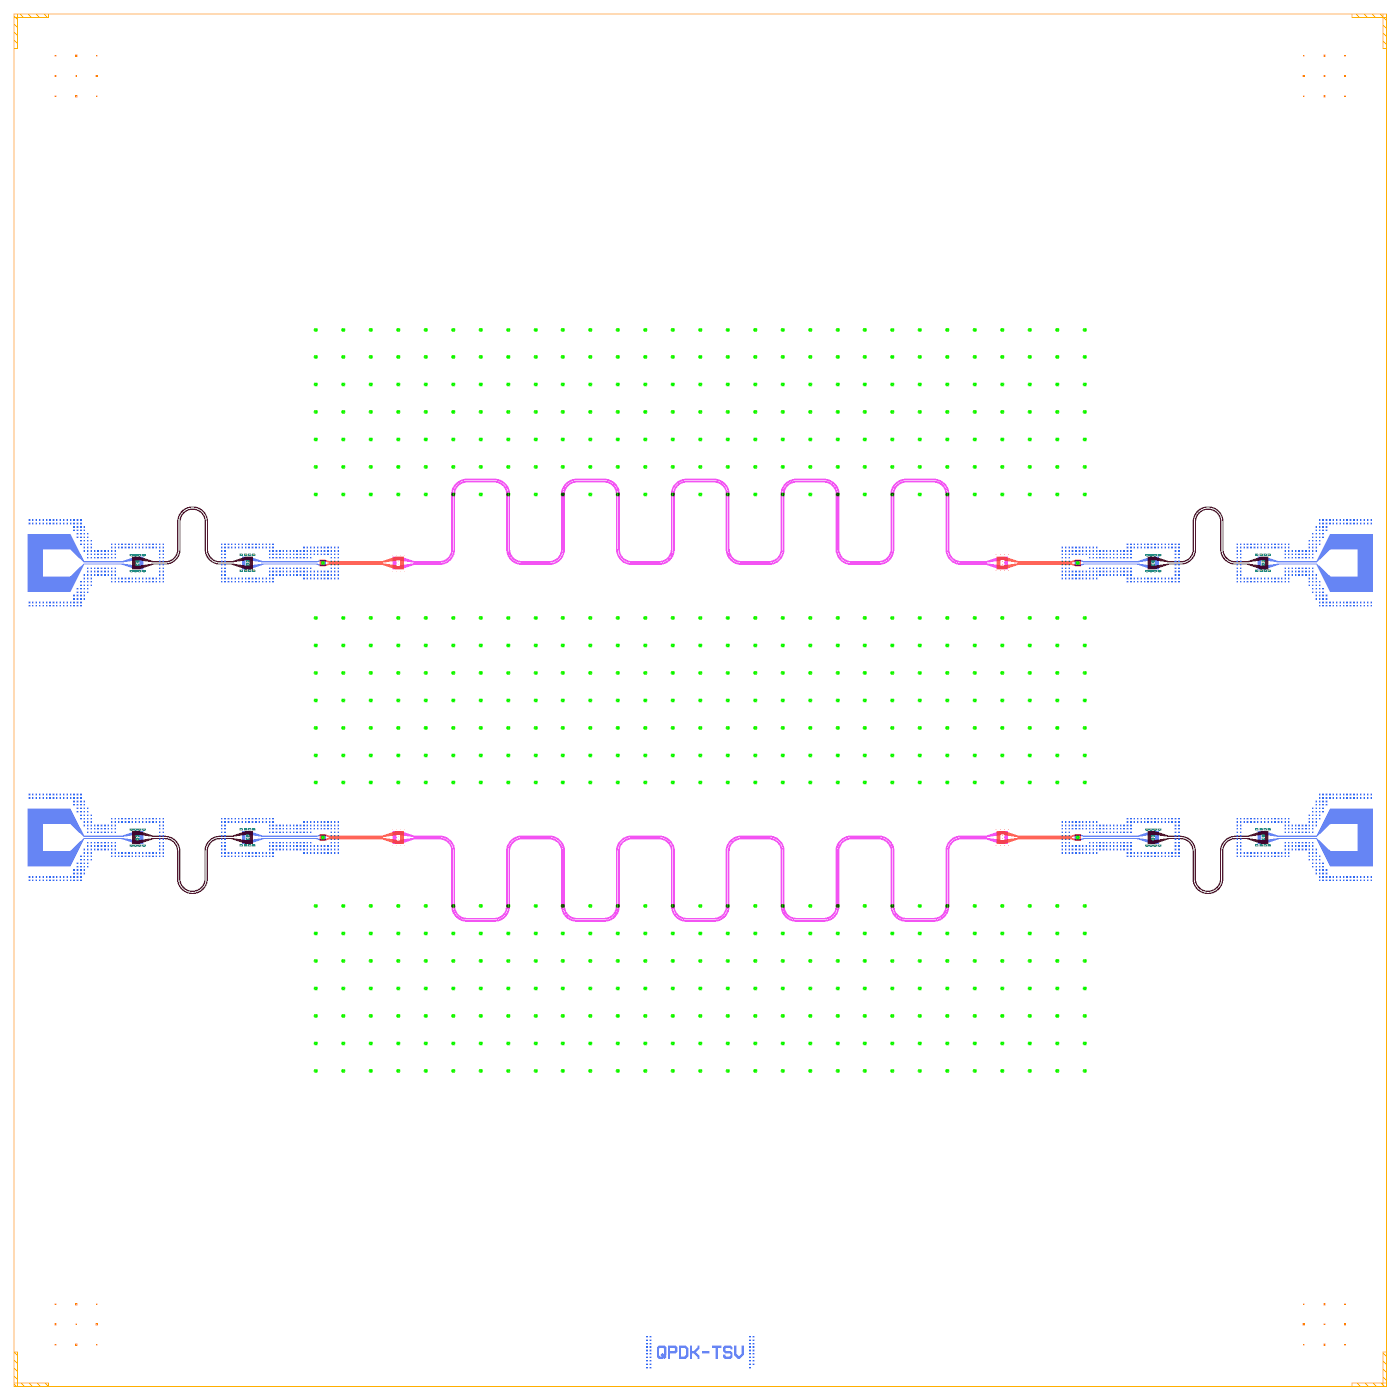

**On the chip so far:** 4 pads · 0 qubits · 625 other components · 18 routes · 0 declared couplings. **This step added** nothing new to the layout.

**1t1** (M1)

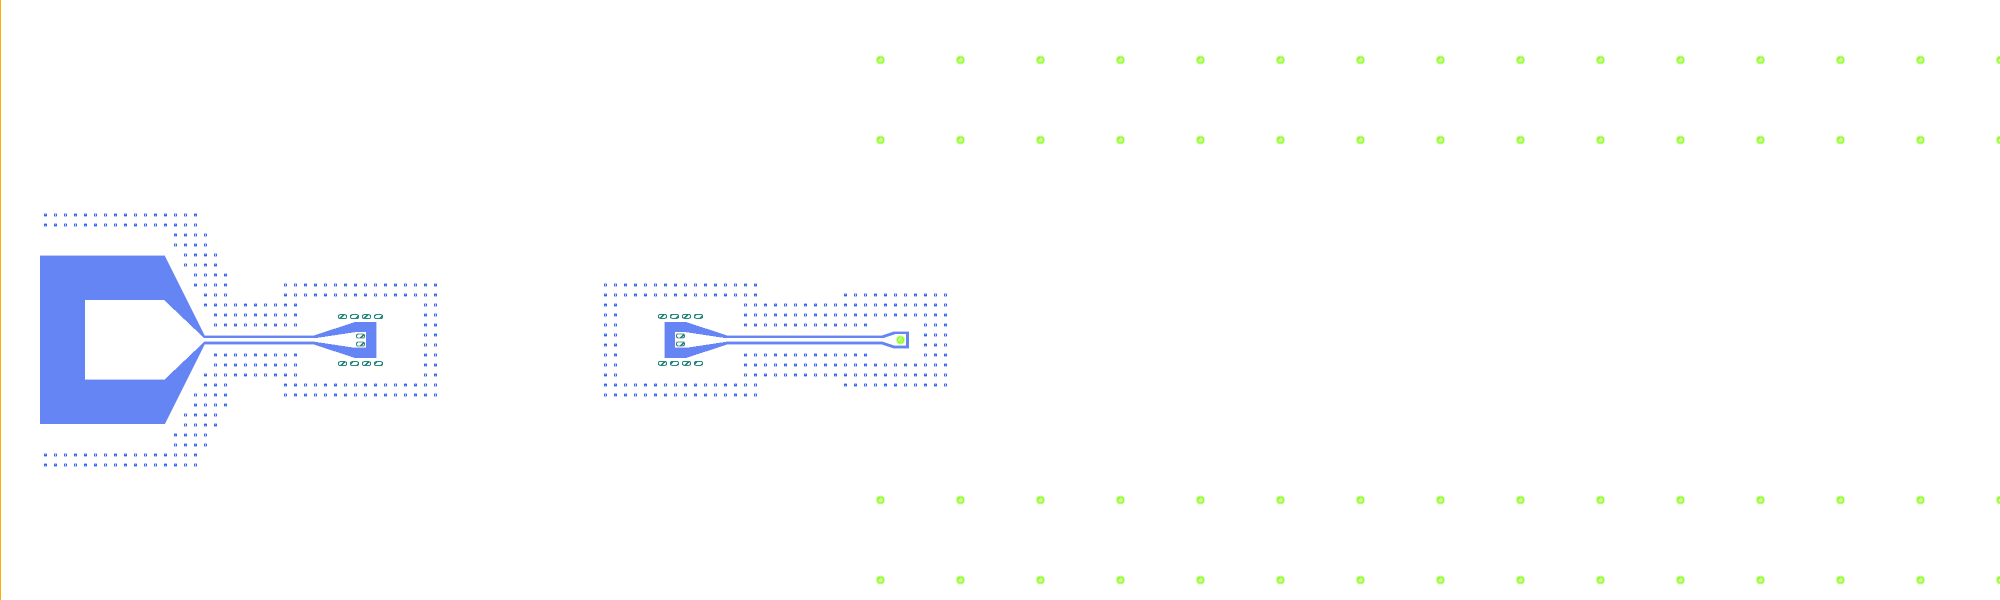

**1b1** (MB)

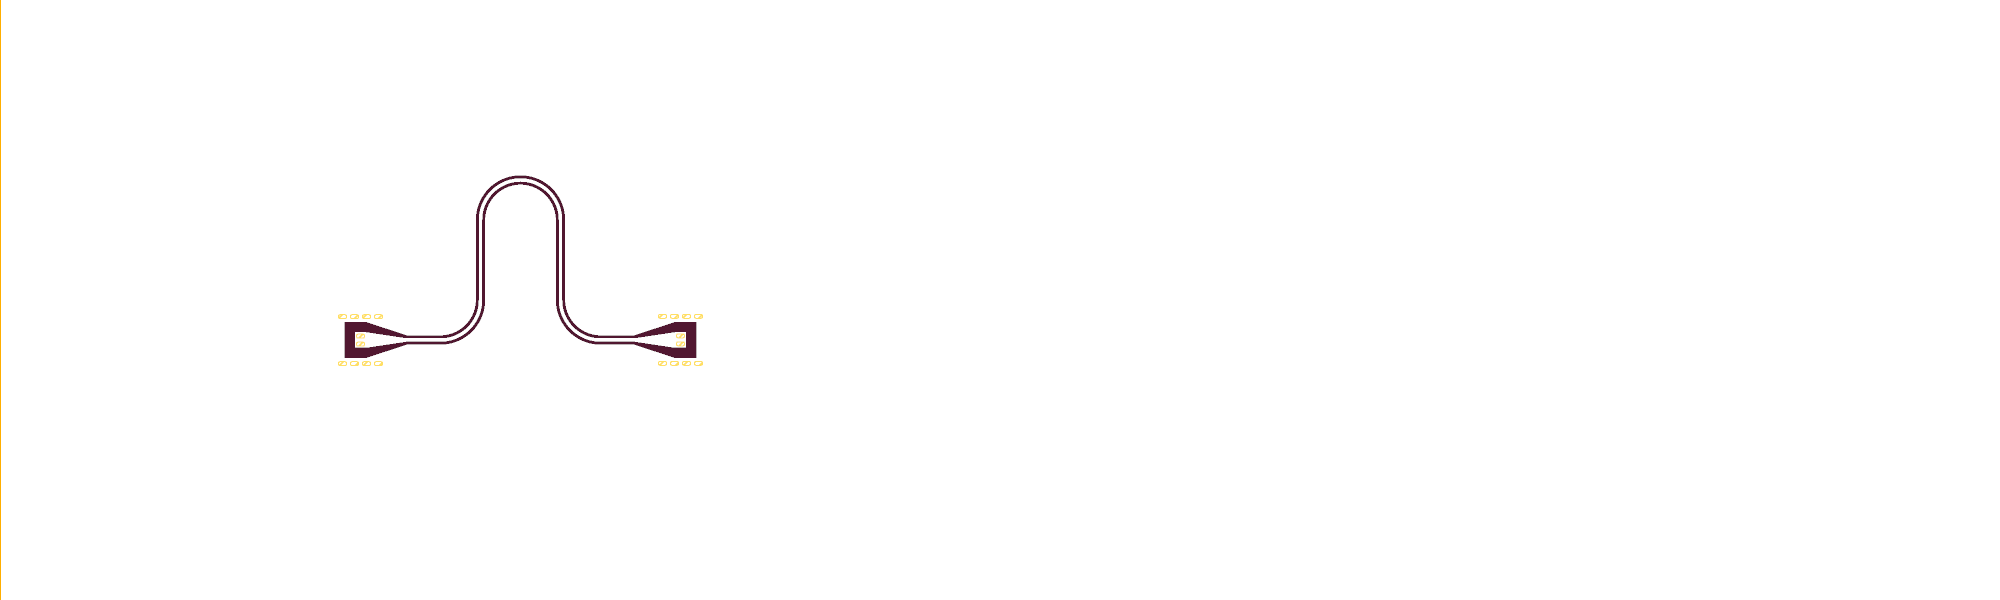

**2b1** (M2)

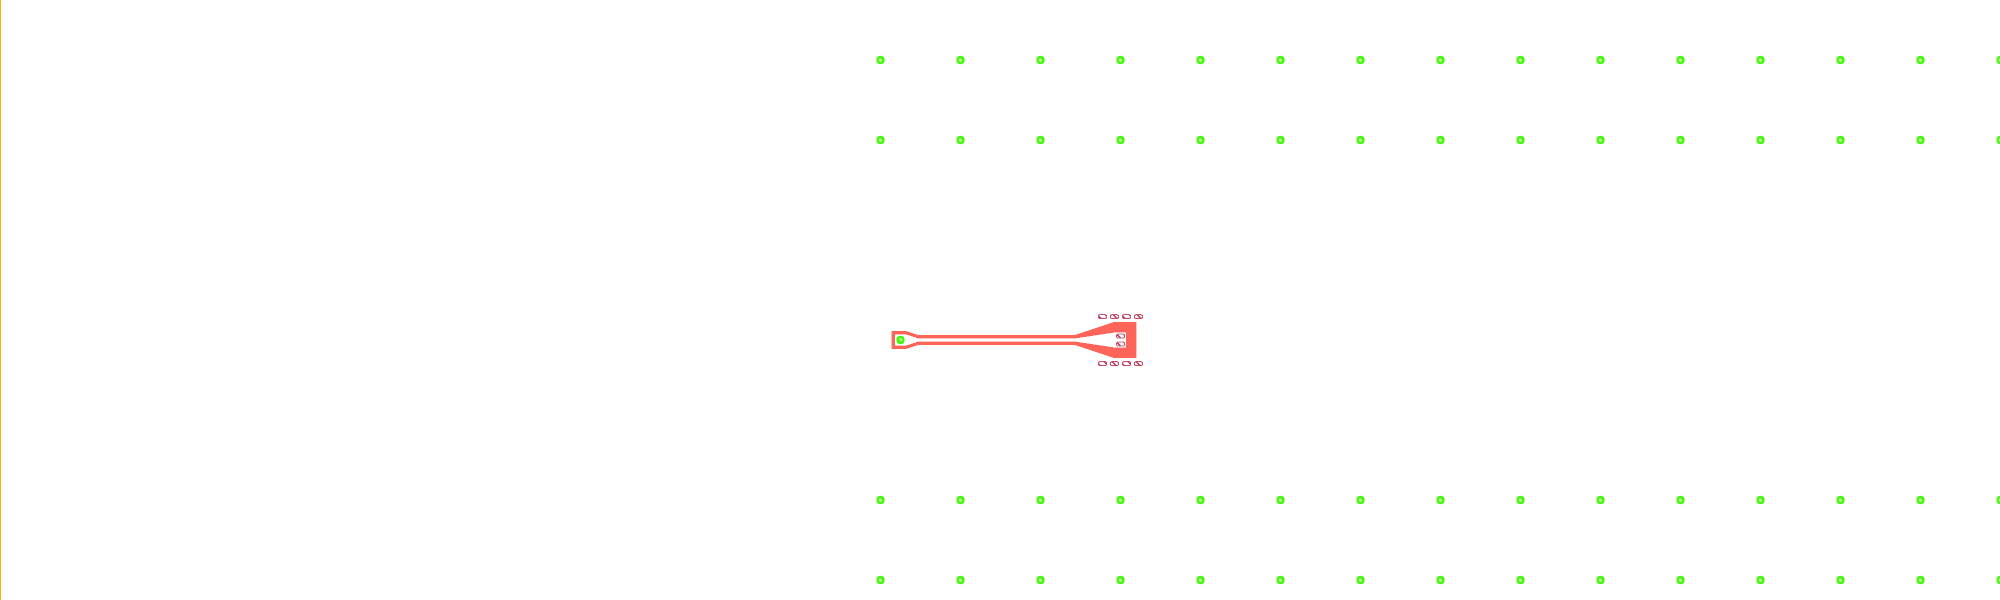

**2t1** (MB2)

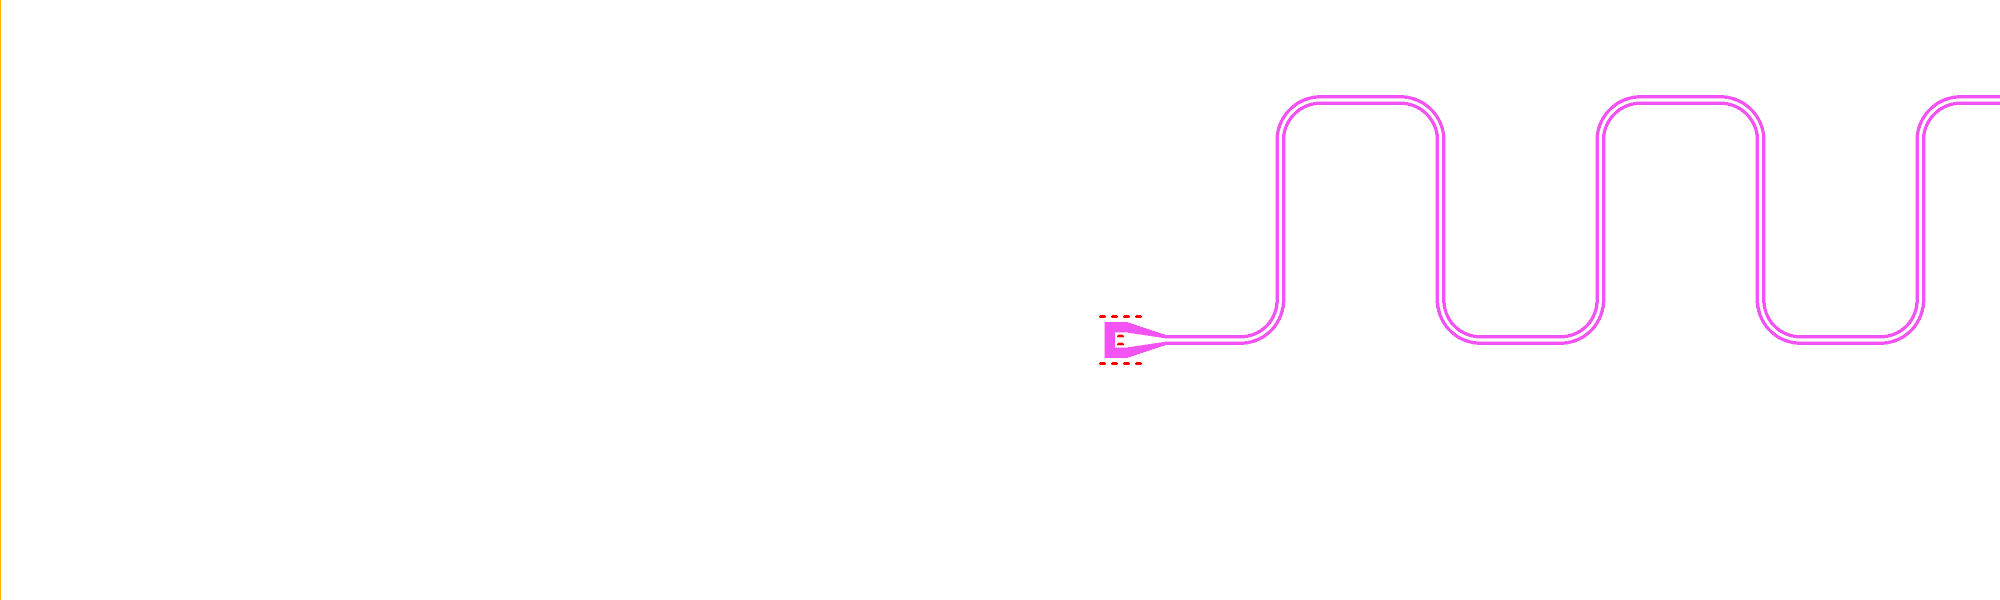

In [14]:
def face_snap(png, face, box, size=(2000, 600), width=760):
    """One metal face on its own: the layers of the other three faces hidden (the die frame stays)."""
    rebuild(d)
    png = snapshot(d.out, png, size=size, box=box, hide=HIDE + tuple(f for f in FACES if f != face))
    display(Image(filename=str(png), width=width))
    return png


for group, inst in (("TSV_IN_A", "TDN_IN_A"), ("BUMP_IN_A", "B_IN_A"), ("TSV_TOP_A", "TT_IN_A")):
    d.sim_group(group, [inst], margin_um=60, analyses=["q3d_cmatrix", "hfss_driven"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "tsv_flip_chip_test_chip.json")
display(Markdown(same))
print(d, "→", DESIGN)
print({k: round(v, 1) for k, v in d.result.route_lengths().items() if k.endswith("_A")})
layout_step(d, STEPS / "s9_chip.png", size=(1400, 1400), width=480)
WEST_A = (0, DY + 350, 5000, DY + 1850)          # the west half of line a
for face in FACES:
    display(Markdown(f"**{face}** ({dict(zip(FACES, ('M1', 'MB', 'M2', 'MB2')))[face]})"))
    face_snap(STEPS / f"s9_{face}.png", face, WEST_A)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends,
metal outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to
read. **PDK design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`,
`pdk_claw`): flagged, never enforced; the rebuild keeps the source's choices. `pdk_report` adds the cheese
source, the centring and the junction types.

The DRC checks each face on its own: two components overlap only where they draw on a common face, each route end is
checked against the etch of the face it is drawn on, and lines on different faces do not cross. **Expected here:** no
errors, no warnings, no PDK design warning. `pdk_report` gives the PDK band as the cheese, the content centred (0, 0)
and no junctions.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit from the components' LOM models: each launcher is a 50 Ω port, a
route between two ports is one conductor, and `CpwTsvTransition` and `QcFlipChipConnectorRf` are pass-through
sections of the line they join. So each line, with its four faces, six TSV transitions and two bumps, is one node
between two 50 Ω ports. The table has three nodes (ground and one per line) and four branches (the four ports), and
lists the cells that form each line's node.

In [ ]:
lb = d.lom()
show_netlist(lb)

# LOM: nothing to simulate

There are no junctions, qubits or resonators: the netlist of Check 2 is two conductors, each between two 50 Ω
launchers, so there is no normal mode to compute. A transition adds no lumped L or C either (the via height, the bump
and the width steps are not in the LOM). What the chip measures, the continuity and return loss of every face
transition and the delay of the MB2 serpentine, is an S-parameter problem: the driven jobs below.

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the C-matrices, the driven runs

The plugin's *Simulate* step. Each job is a sim group cut out of the chip, written to
`build/jobs/<design>_<group>_<analysis>/`. With `RUN_FEM = False` (the default) the jobs are only exported: the cells
load results that were solved and kept before (in `examples/designs/qpdk/fem/<job>/`), and otherwise say what would
appear.

## Simulate 1 · Export to HFSS

A sim group is simulated on every chip face its lines run on: the export reads the faces from the selection (the
transition's ports and vias) and stacks them as KQC does (`1b1`, `1t1`, `2b1`, `2t1`, the PDK substrate under each
chip, the PDK's 8 µm gap between the chips). TSVs and the bump are PEC pillars joining the faces, so each group's line
is one net. A line that leaves the box on another face gets its port on that face: an edge port for Q3D, a wave port
for the driven run. The second table lists, per group, the faces simulated and the ports that are not on 1t1.
`FEM_FAST` (the switch at the top) picks the fast test settings. The driven jobs keep the library's default
frequencies (adaptive mesh at 6 GHz, sweep 4 to 9 GHz). CLI: `qcc sim run build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/qpdk/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group
jobs_drv = export_sims(DESIGN, analysis="hfss_driven")   # driven S-parameters, the same boxes
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_drv).split("\n", 2)[2]))
display(Markdown("| group | faces simulated | ports not on 1t1 |\n|---|---|---|\n" + "\n".join(
    f"| {g} | {', '.join(s.geometry.get('face_stack') or ['1t1'])} | "
    f"{', '.join(f'port {k}: {v}' for k, v in (s.geometry.get('port_faces') or {}).items()) or '–'} |"
    for g, (_, s) in jobs.items())))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each group's line net to ground across the faces it runs on. `fem_stage` solves each job with
`RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))

## Simulate 3 · Full-wave (driven) runs

HFSS driven modal runs of the same boxes, with a wave port on each line the box cuts, on that line's face: S11 and
S21 of the TSV transition through the bottom chip, of the bump transition between the chips, and of the TSV through
the top chip.

In [ ]:
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · driven": k for g, k in keep_drv.items()})))

# Results: the layout against the source, and the FEM values

## Results 1 · QPDK's own picture

gdsfactory (QPDK's layout engine) is not installed in this environment, so the source is not rebuilt here for an
XOR; QPDK's own render of the chip is shown from the local clone when it is there. Compare it with the whole chip of
Design 9: the same lines, transitions, serpentines and bump arrays; QPDK also draws the two 100 µm chip edges, this
rebuild the Quantcore die frame instead of the bottom one and nothing for the top one.

In [ ]:
SRC_IMG = Path("build/external/quantum-rf-pdk/docs/_static/images") / "tsv_flip_chip_test_chip.png"   # QPDK's render (MIT)
if SRC_IMG.exists():
    display(Image(filename=str(SRC_IMG), width=420))
else:
    print("QPDK image not in this checkout: "
          "https://github.com/gdsfactory/quantum-rf-pdk/blob/main/docs/_static/images/tsv_flip_chip_test_chip.png")

## Results 2 · The values

Each kept Q3D job's C-matrix (its line net to ground), and where each kept driven job's S-parameters are. No
multi-face job of the library has been solved yet, so these cells print one line until a solve is kept.

In [ ]:
shown = False
for g, k in keep_q3d.items():
    if k:
        display(Markdown(f"**{g}** (Q3D)\n\n" + cmatrix_md(k)))
        shown = True
for g, k in keep_drv.items():
    if k:
        res = json.loads((Path(k) / "results" / "results.json").read_text(encoding="utf-8"))
        display(Markdown(f"**{g}** (driven): kept results in `{(Path(k) / 'results').as_posix()}`; "
                         f"S-parameter entries: {', '.join(sorted(res.get('sparams') or {})) or 'none'}"))
        shown = True
if not shown:
    print("No FEM results yet (RUN_FEM = True): this cell would list each group's C-matrix and where its S11 / S21 are.")

## Results 3 · Feedback: none

There is no target to iterate towards: the source states none, and the lines follow QPDK's positions and
waypoints. A variant (another taper, pad or via count) is a new layout, checked again by the DRC, the netlist and the
driven jobs.

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `tsv_flip_chip_test_chip.json` (saved in Design 9) is the whole design: `qcc build
examples/designs/qpdk/tsv_flip_chip_test_chip.json` rebuilds `build/tsv_flip_chip_test_chip.oas` and its sidecar,
and the KLayout plugin, `qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 of the front face (with the cheese),
the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm, each TSV transition's box around its
pads, tapers and vias; 3/0 also holds every cheese hole), the TSVs on 700/0 (the vias as drawn on 1t1 and 2b1, so
both chips' vias), the top chip's front etch on 800/0, the bumps on 801/0 and their under-bump metal on 802/0, and the
frame (100/0, 1000/0, 1001/0). **The two backside faces have no fab layer in PDK v3:** their etch (1b1 and 2t1
`base_metal_gap_wo_grid`: the underpasses, the serpentines, the backside pads and tapers) and their copies of the
vias are left out, and `export_fab` says so with a `FabLayersDropped` warning (the last line of the table lists them).
The cheese source is `build`: the PDK band drawn in the build, around the front-face features only and at least 13 µm
from every TSV and bump. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/qpdk/tsv_flip_chip_test_chip.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The full die (compare QPDK's picture in Results 1); the TSV transition `TDN_IN_A` with its two lines; the bump
transition `B_IN_A` with its two lines; the die frame's south-west corner (dicing L on 1000/0, 3 × 3 alignment grid on
1001/0); and `TDN_IN_A` in the **fab view** (the mask from Fab 1): only the front pad, its taper and the vias are
there, the back pad, its taper and the underpass are not in the mask.

In [ ]:
show_snapshot(d, OUT / "tsv_flip_chip_test_chip.png", size=(1600, 1600))
TSV_BOX = (DX - 4100 - 160, DY + 1000 - 100, DX - 4100 + 160, DY + 1000 + 100)
show_snapshot(d, OUT / "tsv_flip_chip_test_chip_tsv.png", box=TSV_BOX, size=(1280, 800), width=520)
show_snapshot(d, OUT / "tsv_flip_chip_test_chip_bump.png",
              box=(DX - 2750 - 130, DY + 1000 - 95, DX - 2750 + 130, DY + 1000 + 95), size=(1300, 950), width=420)
show_snapshot(d, OUT / "tsv_flip_chip_test_chip_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "tsv_flip_chip_test_chip_fab.oas", OUT / "tsv_flip_chip_test_chip_fab_tsv.png", box=TSV_BOX,
          size=(1280, 800), width=520);

## Summary

| | |
|---|---|
| **matches the source** | the two lines with QPDK's transition, bump and waypoint positions; the TSV transitions (`CpwTsvTransition` at QPDK's defaults: tapers, pads, gaps, vias); the bump transitions' pads, gap and bump; the serpentines and underpasses; the 609 ground bumps; CPW 10 / 6 µm, r = 100 µm on every face |
| **differs (PDK)** | the Quantcore die frame on the bottom chip, nothing for the top chip's edge; launcher ports 110 µm further in (`BondPad`); sapphire; the PDK cheese band on the front face; the backside faces (1b1, 2t1) are not in the fab mask (no PDK fab layer) |
| **simplified** | KQC's bump cell: a 30 µm taper (QPDK 10 µm) and an under-bump metal (⌀ 20 µm) on every bump; a waypoint 20 µm out of each underpass port (the router's stub, same centre line) |
| **PDK design warnings** | none (pads at 100 µm, no junctions) |
| layout | built in nine segments (die, launchers, transitions, M1 lines, MB underpasses, M2 lines, MB2 serpentines, ground bumps, the whole chip) |
| LOM | none: two through lines; the transitions are pass-through sections with no lumped L or C |
| FEM | three sim groups (a bottom-chip TSV, a bump, a top-chip TSV), Q3D and driven, exported on their faces, not solved (`RUN_FEM = False`; no multi-face job has been solved with the library yet) |
| open | the backside faces need PDK fab layers before they reach a mask |